In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

df = pd.read_csv("../data/raw/DataCoSupplyChainDataset.csv", encoding= "latin-1", sep=",")
columns_to_drop = [
    "Product Description",
    "Order Zipcode",
    "Customer Password"
]

df_clean = df.drop(columns=columns_to_drop).copy()

df_clean["order date (DateOrders)"] = pd.to_datetime(
    df_clean["order date (DateOrders)"],
    errors="coerce"
)

df_clean["shipping date (DateOrders)"] = pd.to_datetime(
    df_clean["shipping date (DateOrders)"],
    errors="coerce"
)

print(f"Dataset shape: {df_clean.shape}")


Dataset shape: (180519, 50)


## 1. Shipping Mode Distribution

This analysis examines the distribution of orders across shipping modes.
Understanding shipping-mode usage provides context for subsequent comparisons
of logistics performance.

Shipping Mode Counts


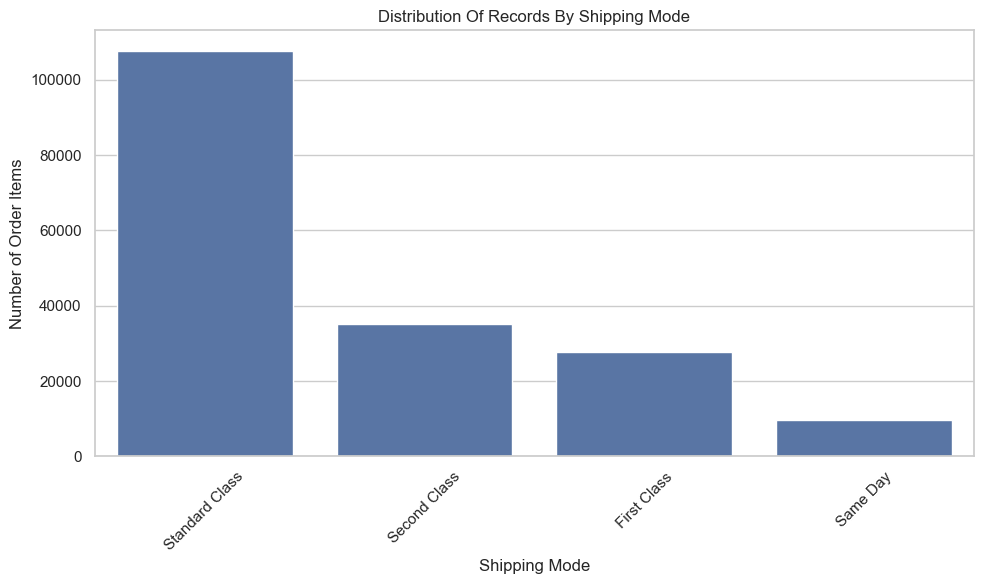

In [3]:
shipping_counts = (df_clean["Shipping Mode"].value_counts())
print("Shipping Mode Counts")

plt.figure(figsize=(10, 6))

sns.barplot(x=shipping_counts.index, y=shipping_counts.values)

plt.title("Distribution Of Records By Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Number of Order Items")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [4]:
# examining late delivery risk by shipping mode

risk_by_mode = (
    df_clean.groupby("Shipping Mode")["Late_delivery_risk"].mean().mul(100).sort_values(ascending=False)
)

print(risk_by_mode.round(2))

Shipping Mode
First Class       95.32
Second Class      76.63
Same Day          45.74
Standard Class    38.07
Name: Late_delivery_risk, dtype: float64


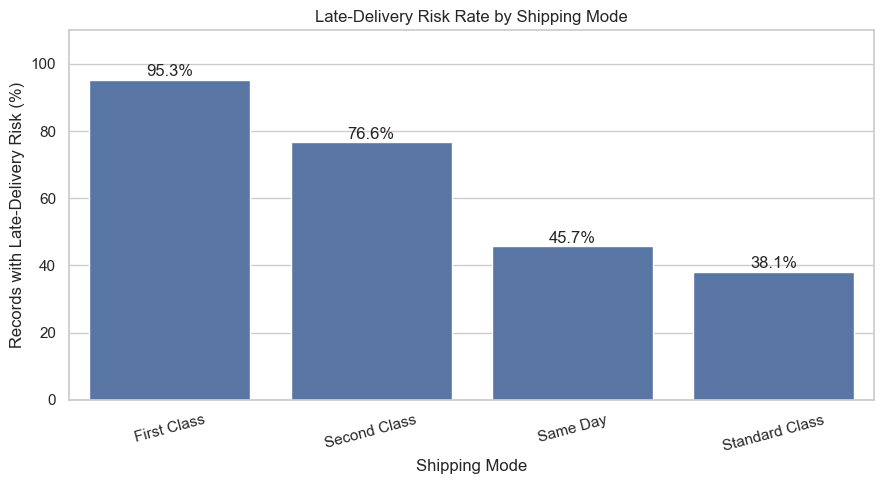

In [8]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=risk_by_mode.index,
    y=risk_by_mode.values
)

plt.title("Late-Delivery Risk Rate by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Records with Late-Delivery Risk (%)")
plt.xticks(rotation=15)

for i, value in enumerate(risk_by_mode.values):
    plt.text(i, value + 1, f"{value:.1f}%", ha="center")

plt.ylim(0, 110)
plt.tight_layout()
plt.show()

In [11]:
shipping_time_summary = (
    df_clean.groupby("Shipping Mode")[
        [
            "Days for shipping (real)",
            "Days for shipment (scheduled)"
        ]
    ]
    .mean()
    .sort_values("Days for shipping (real)", ascending=False)
)

shipping_time_summary

,Days for shipping (real),Days for shipment (scheduled)
Shipping Mode,,
Standard Class,3.995907,4.0
Second Class,3.990828,2.0
First Class,2.000000,1.0
Same Day,0.478279,0.0


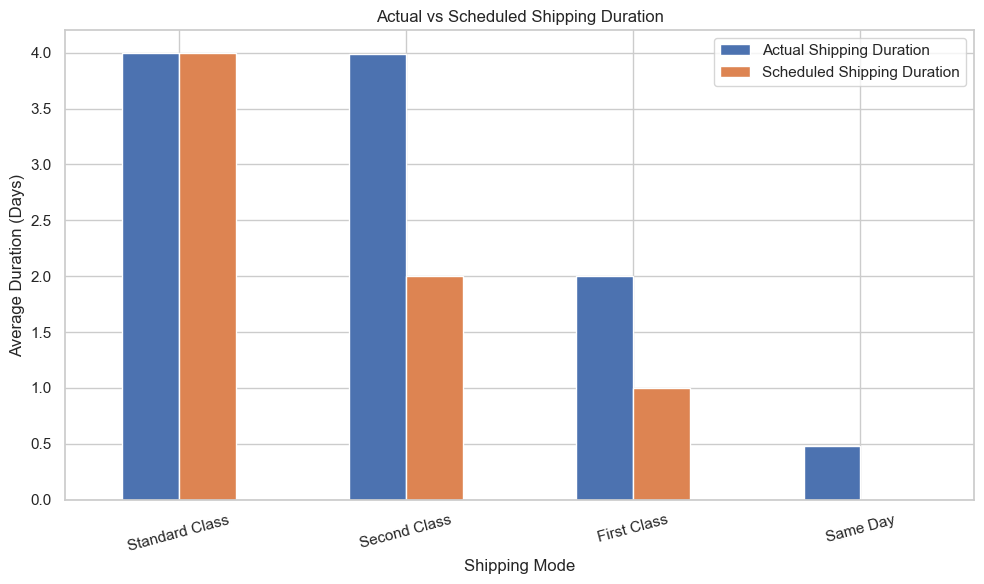

In [13]:
shipping_time_summary.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Actual vs Scheduled Shipping Duration")
plt.xlabel("Shipping Mode")
plt.ylabel("Average Duration (Days)")
plt.xticks(rotation=15)
plt.legend(
    ["Actual Shipping Duration", "Scheduled Shipping Duration"]
)
plt.tight_layout()
plt.show()